# Insider wallet EDA
Broad descriptive EDA of the supplied wallet feature and score tables. October 29, 2026. Other wallets have unknown insider status. Source cohort: five event groups described in the student demo, April 2025–March 2026.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
ROOT=Path('/Users/joshuavu/SCHOOL /Stats C161/Project')
DATA=ROOT/'L3_prediction_markets_student_package_2026-10-07/notebooks/data'
a=pd.read_csv(DATA/'wallet_features.csv'); b=pd.read_csv(DATA/'wallet_scores.csv')
features=a.select_dtypes('number').columns.tolist()
print('Feature and score shapes:',a.shape,b.shape)
print('Labels:',a.confirmed.value_counts().to_dict())
print('Missing:',a.isna().sum().sum(),'Duplicate wallet IDs:',a.wallet.duplicated().sum())
display(a.describe().T)
display(a.groupby('confirmed')[features].agg(['median','mean','min','max']).T)

Feature and score shapes: (55952, 11) (55668, 15)
Labels: {False: 55933, True: 19}
Missing: 0 Duplicate wallet IDs: 0


,count,mean,std,min,25%,50%,75%,max
trade_count,55952.0,74.888243,765.536114,3.000000,5.000000,10.000000,24.000000,5.988500e+04
unique_markets,55952.0,9.041464,23.006774,1.000000,3.000000,4.000000,8.000000,1.177000e+03
total_notional,55952.0,10481.786812,163481.228852,0.011400,46.421594,197.841175,982.089187,1.971762e+07
avg_buy_price,55952.0,0.669188,0.272842,0.001000,0.519950,0.732745,0.902192,9.990000e-01
concentration,55952.0,0.560874,0.255401,0.008329,0.357143,0.526763,0.759686,1.000000e+00
max_single_buy,55952.0,965.975317,8832.583882,0.004950,18.600000,63.951150,305.290822,1.016632e+06
market_notional_ratio,55952.0,0.004405,0.029763,0.000000,0.000018,0.000117,0.000669,1.000000e+00
wallet_age_days,55952.0,47.750300,69.911205,0.000000,4.789007,20.841204,50.745530,3.626167e+02
position_anomaly_ratio,55952.0,2.048703,2.325015,0.002622,1.035031,1.557361,2.364895,1.711854e+02


confirmed                             False         True 
trade_count            median  1.000000e+01  1.550000e+02
                       mean    7.474866e+01  4.857895e+02
                       min     3.000000e+00  7.000000e+00
                       max     5.988500e+04  3.753000e+03
unique_markets         median  4.000000e+00  8.000000e+00
                       mean    9.039404e+00  1.510526e+01
                       min     1.000000e+00  1.000000e+00
                       max     1.177000e+03  6.800000e+01
total_notional         median  1.976188e+02  4.266808e+04
                       mean    1.037464e+04  3.259034e+05
                       min     1.140000e-02  1.865159e+03
                       max     1.971762e+07  3.900381e+06
avg_buy_price          median  7.327870e-01  6.607210e-01
                       mean    6.692148e-01  5.900225e-01
                       min     1.000000e-03  1.000000e-01
                       max     9.990000e-01  9.159270e-01
concentration          median  5.267640e-01  4.154350e-01
                       mean    5.608972e-01  4.926115e-01
                       min     8.329000e-03  1.050090e-01
                       max     1.000000e+00  1.000000e+00
max_single_buy         median  6.389440e+01  6.400000e+03
                       mean    9.605267e+02  1.700596e+04
                       min     4.950000e-03  2.100000e+02
                       max     1.016632e+06  8.742782e+04
market_notional_ratio  median  1.170000e-04  1.126100e-02
                       mean    4.389850e-03  4.894458e-02
                       min     0.000000e+00  5.100000e-05
                       max     1.000000e+00  2.612970e-01
wallet_age_days        median  2.084123e+01  1.146132e+01
                       mean    4.773456e+01  9.409386e+01
                       min     0.000000e+00  0.000000e+00
                       max     3.626167e+02  3.005139e+02
position_anomaly_ratio median  1.557446e+00  8.273990e-01
                       mean    2.048900e+00  1.467645e+00
                       min     2.622000e-03  2.100160e-01
                       max     1.711854e+02  4.645102e+00

## Feature distributions
Within-group density makes the 19 confirmed wallets visible despite the imbalance. Log transforms reduce the influence of large values. Notional represents trading activity, not profit.

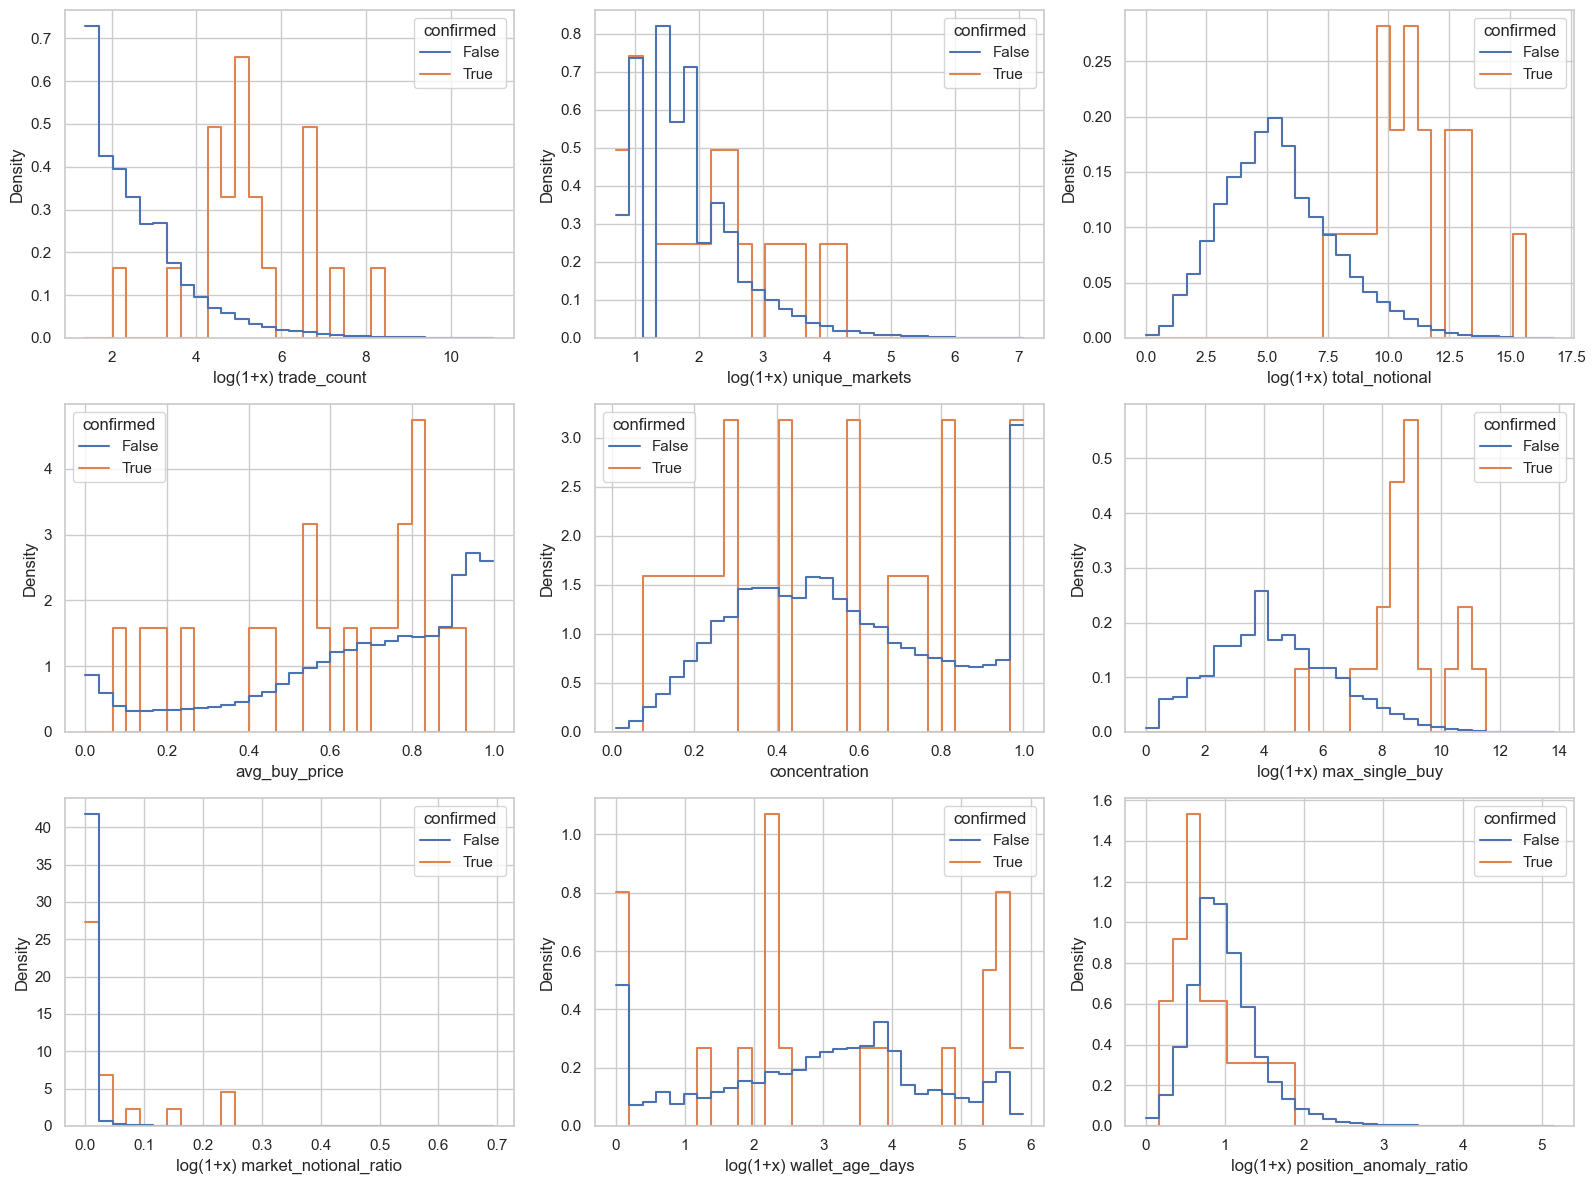

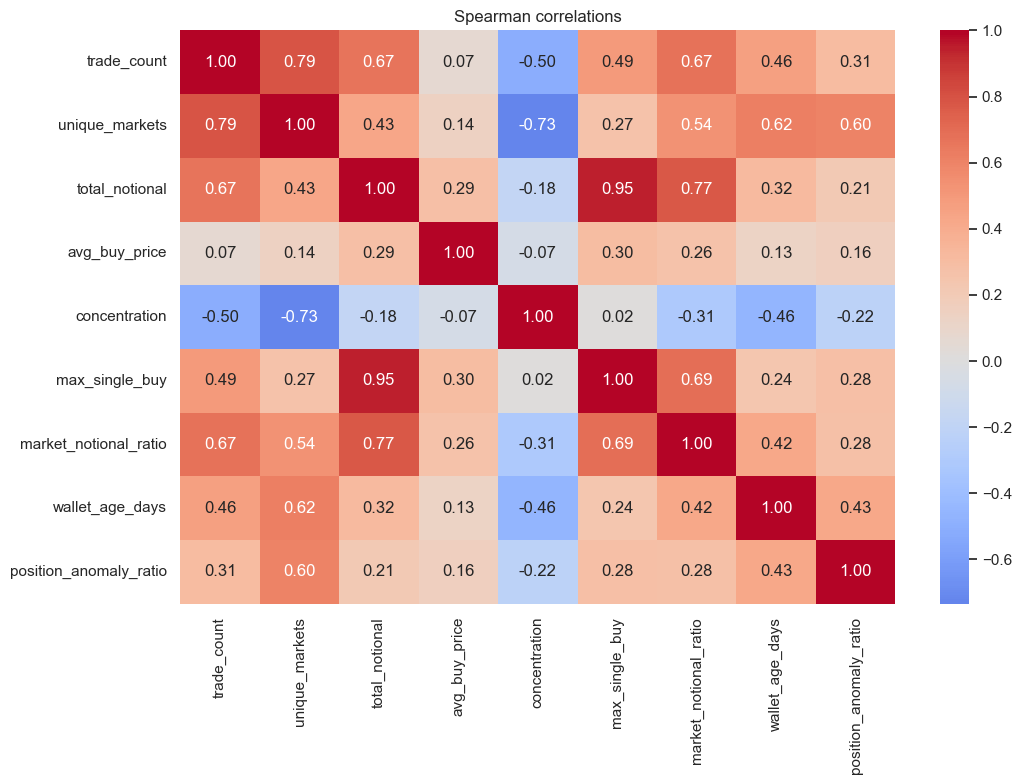

In [2]:
sns.set_theme(style='whitegrid')
fig,axes=plt.subplots(3,3,figsize=(16,12))
for ax,col in zip(axes.flat,features):
    log=col not in ['avg_buy_price','concentration']
    sns.histplot(x=np.log1p(a[col]) if log else a[col],hue=a.confirmed,common_norm=False,stat='density',element='step',fill=False,bins=30,ax=ax)
    ax.set_xlabel(('log(1+x) ' if log else '')+col)
plt.tight_layout();plt.show()
plt.figure(figsize=(11,8));sns.heatmap(a[features].corr(method='spearman'),annot=True,fmt='.2f',cmap='coolwarm',center=0);plt.title('Spearman correlations');plt.tight_layout();plt.show()

## Insider profiles and age
Mean age is higher for confirmed wallets while median age is lower. Zero observed age does not establish a new blockchain account. Large known insiders may be overrepresented because public reporting can favor visible trades.

In [3]:
pos=a[a.confirmed];other=a[~a.confirmed]
display(pos.sort_values('total_notional',ascending=False))
for col,edges in [('wallet_age_days',[0,1,7,14,30,90,200,400]),('total_notional',[0,100,1000,10000,100000,1000000,np.inf])]:
    print(col);display(pd.crosstab(pd.cut(a[col],edges,right=False),a.confirmed,normalize='columns')*100)
print('Median ratios, confirmed / other:');display(pos[features].median()/other[features].median())
print('Largest insider share of insider notional:',pos.total_notional.max()/pos.total_notional.sum())

,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
20983,w_5b2b2d0846,3753,68,3.900381e+06,0.915927,0.105009,62847.889200,0.261297,275.294016,1.095702,True
18651,w_2a43266bd8,1332,55,6.754869e+05,0.896895,0.146908,49900.000000,0.260756,300.513912,4.062995,True
17114,w_b484b941ed,677,26,4.893592e+05,0.660721,0.579091,87427.821600,0.011261,244.998530,4.645102,True
45220,w_bc876cca82,742,22,3.594356e+05,0.787750,0.251212,9910.000000,0.150682,41.889109,0.606562,True
30878,w_bae5b984cf,870,13,2.972208e+05,0.561984,0.291078,36014.956800,0.093145,39.845891,1.575241,True
36341,w_651e7829e2,178,8,1.051164e+05,0.815197,0.302090,9939.552000,0.034399,241.939954,0.756461,True
6257,w_cd38860893,155,2,7.532742e+04,0.584896,0.705602,7909.984740,0.004086,2.252280,0.210016,True
2411,w_d1a074f023,199,6,6.532571e+04,0.726557,0.415435,8412.962400,0.025531,208.945579,0.772709,True
24407,w_bf68f8e7eb,134,9,4.602897e+04,0.821888,0.197589,3686.464504,0.001504,5.685197,0.720811,True
42221,w_45933e3f6b,136,3,4.266808e+04,0.533400,0.577474,6400.000000,0.039752,9.531840,0.449985,True


wallet_age_days


confirmed,False,True
wallet_age_days,,
"[0, 1)",13.734289,15.789474
"[1, 7)",16.203315,10.526316
"[7, 14)",11.215204,26.315789
"[14, 30)",18.457798,0.000000
"[30, 90)",24.781435,10.526316
"[90, 200)",8.165126,5.263158
"[200, 400)",7.442833,31.578947


total_notional


confirmed,False,True
total_notional,,
"[0.0, 100.0)",37.117623,0.000000
"[100.0, 1000.0)",38.156366,0.000000
"[1000.0, 10000.0)",17.647900,15.789474
"[10000.0, 100000.0)",5.740797,52.631579
"[100000.0, 1000000.0)",1.158529,26.315789
"[1000000.0, inf)",0.178785,5.263158


Median ratios, confirmed / other:


trade_count                15.500000
unique_markets              2.000000
total_notional            215.910981
avg_buy_price               0.901655
concentration               0.788655
max_single_buy            100.165273
market_notional_ratio      96.247863
wallet_age_days             0.549935
position_anomaly_ratio      0.531254
dtype: float64

Largest insider share of insider notional: 0.6298896547692255


## Ranking comparisons and exclusions
Use exactly the same 55,668 scored wallets for each ranking. This comparison has 18 positive labels and no held-out test. The supplied bot heuristic removes one confirmed wallet.

Excluded: 284 Confirmed excluded: 1


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
20983,w_5b2b2d0846,3753,68,3.900381e+06,0.915927,0.105009,62847.8892,0.261297,275.294016,1.095702,True


,fraction,k,ranking,captured,recall,precision
0,0.001,56,score,0,0.000000,0.000000
1,0.001,56,total_notional,0,0.000000,0.000000
2,0.001,56,max_single_buy,1,0.055556,0.017857
3,0.001,56,trade_count,0,0.000000,0.000000
4,0.001,56,unique_markets,0,0.000000,0.000000
5,0.001,56,market_notional_ratio,0,0.000000,0.000000
6,0.001,56,position_anomaly_ratio,0,0.000000,0.000000
7,0.010,557,score,1,0.055556,0.001795
8,0.010,557,total_notional,5,0.277778,0.008977
9,0.010,557,max_single_buy,3,0.166667,0.005386


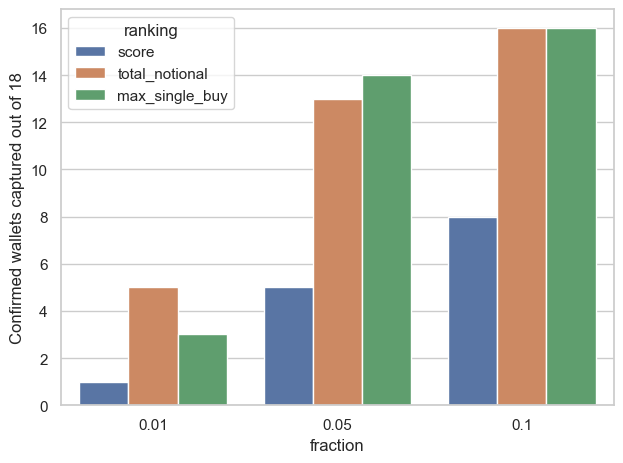

In [4]:
excluded=a[~a.wallet.isin(b.wallet)]
print('Excluded:',len(excluded),'Confirmed excluded:',int(excluded.confirmed.sum()));display(excluded[excluded.confirmed])
rows=[]
for q in [.001,.01,.05,.1]:
    k=int(np.ceil(len(b)*q))
    for f in ['score','total_notional','max_single_buy','trade_count','unique_markets','market_notional_ratio','position_anomaly_ratio']:
        hits=int(b.nlargest(k,f).confirmed.sum());rows.append(dict(fraction=q,k=k,ranking=f,captured=hits,recall=hits/b.confirmed.sum(),precision=hits/k))
capture=pd.DataFrame(rows);display(capture)
v=capture[capture.fraction.isin([.01,.05,.1]) & capture.ranking.isin(['score','total_notional','max_single_buy'])]
sns.barplot(data=v,x='fraction',y='captured',hue='ranking');plt.ylabel('Confirmed wallets captured out of 18');plt.tight_layout();plt.show()

## Entertainment inventory
Preliminary title keyword screen, requiring manual relevance review. Matching a resolution record does not establish usable trade coverage. Demo w_ pseudonyms cannot be linked to raw 0x addresses without a mapping.

In [5]:
con=duckdb.connect()
ent=con.execute("""select m.slug,m.title,m.event_slug,r.resolved_yes,r.resolved_at from read_parquet(?) m left join read_parquet(?) r on m.slug=r.market_slug where regexp_matches(lower(m.title),'box office|oscars|grammys|spotify|billboard|emmys')""",[str(ROOT/'data/catalog/markets.parquet'),str(ROOT/'data/catalog/resolutions.parquet')]).df()
print('Rows:',len(ent),'Distinct markets:',ent.slug.nunique(),'Events:',ent.event_slug.nunique(),'Resolution matches:',ent.resolved_yes.notna().sum());display(ent.head(30))

Rows: 1216 Distinct markets: 1216 Events: 208 Resolution matches: 457


,slug,title,event_slug,resolved_yes,resolved_at
0,will-wildchild-alex-warren-be-the-billboard-20...,"Will ""Wildchild - Alex Warren"" be the Billboar...",billboard-200-1-album-week-of-september-19,<NA>,NaT
1,will-ultimate-dolly-parton-dolly-parton-be-the...,"Will ""Ultimate Dolly Parton - Dolly Parton"" be...",billboard-200-1-album-week-of-september-19,<NA>,NaT
2,will-don-t-look-down-rod-wave-be-the-billboard...,"Will ""Don't Look Down - Rod Wave"" be the Billb...",billboard-200-1-album-week-of-september-19,<NA>,NaT
3,will-you-seem-pretty-sad-for-a-girl-so-in-love...,"Will ""You Seem Pretty Sad for a Girl So in Lov...",billboard-200-1-album-week-of-september-19,<NA>,NaT
4,will-dandelion-ella-langley-be-the-billboard-2...,"Will ""Dandelion - Ella Langley"" be the Billboa...",billboard-200-1-album-week-of-september-19,<NA>,NaT
5,will-the-sin-bliss-enhypen-be-the-billboard-20...,"Will ""THE SIN : BLISS - ENHYPEN"" be the Billbo...",billboard-200-1-album-week-of-september-19,<NA>,NaT
6,will-been-by-now-morgan-wallen-be-the-billboar...,"Will ""Been By Now - Morgan Wallen"" be the Bill...",billboard-hot-100-2-song-week-of-september-19,<NA>,NaT
7,will-hate-that-i-made-you-love-me-ariana-grand...,"Will ""hate that i made you love me - Ariana Gr...",billboard-hot-100-2-song-week-of-september-19,<NA>,NaT
8,will-i-knew-it-i-knew-you-taylor-swift-be-the-...,"Will ""I Knew It, I Knew You - Taylor Swift"" be...",billboard-hot-100-2-song-week-of-september-19,<NA>,NaT
9,will-choosin-texas-ella-langley-be-the-billboa...,"Will ""Choosin' Texas - Ella Langley"" be the Bi...",billboard-hot-100-2-song-week-of-september-19,<NA>,NaT


## Presentation takeaways
- Median traded notional: $42,668 versus $198.
- Median largest buy: $6,400 versus $64.
- Median age: 11.5 versus 20.8 days, despite a higher confirmed mean.
- Concentration is lower at the confirmed median.
- Top 5% by notional captures 13/18 scored labels, versus 5/18 by anomaly score.
- The largest confirmed wallet is absent from the score file.

Limitations: selected cohort, 19 labels, discovery bias, unknown status of comparison wallets, whole-history features, no temporal holdout. No entertainment insider identification or profit finding follows from this analysis.

Sources: supplied CSVs, student README and insider_demo.ipynb for cohort and method, local catalog parquet files for entertainment inventory.